# CNN de gatos y perros · Pipeline para Kaggle

Notebook autónomo: contiene las funciones de `src/` y ejecuta preparación, inspección,
entrenamiento, evaluación y predicción sin importar archivos del repositorio.
Conserva la CNN de cuatro convoluciones, BatchNorm, pooling global, Dropout y Adam
con `weight_decay`. No incorpora aumentación, scheduler ni modelos preentrenados.

**Antes de ejecutar:**
1. Adjunta **Dogs vs. Cats** desde **Add Input** (imágenes `cat.N.jpg` y `dog.N.jpg`, o `train.zip`).
2. Selecciona un acelerador GPU en la configuración del notebook si está disponible.
3. Revisa la celda de configuración y ejecuta las celdas de arriba hacia abajo.

Los datos adjuntos se leen desde `/kaggle/input`; los archivos generados se guardan
bajo `/kaggle/working`. Se usan las bibliotecas del entorno, sin reinstalar PyTorch.
Consulta la [documentación de Kaggle](https://www.kaggle.com/docs/notebooks).
El notebook también admite ejecución local desde la raíz del proyecto.

## 1. Bibliotecas y configuración
`SMOKE_TEST=True` ejecuta una época y dos lotes por conjunto para comprobar el flujo;
no reduce la preparación ni la inspección de imágenes. Sus métricas no representan
rendimiento real. Con `False` se entrena usando todos los datos.

`SOURCE` puede apuntar a una carpeta con imágenes originales o a `train.zip`.
Con `None` se intenta detectar una única fuente. `PREPARED_DATA` permite reutilizar
una división del proyecto con `manifest.json`. La semilla de esa división se conserva.
Cada ejecución de esta celda crea un directorio nuevo de resultados.

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib-cnn")

import csv
import json
import math
import random
import re
import shutil
import zipfile
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from PIL import Image, ImageOps
from torchvision.datasets import ImageFolder
from torchvision.transforms import ToTensor
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path("/kaggle/input") if ON_KAGGLE else Path("/kaggle/input/datasets/kiyotaka35/dataset-dogs-cats-25000/train")
WORK_ROOT = Path("/kaggle/working") if ON_KAGGLE else Path("artifacts/kaggle")
SOURCE = None                 # Ej.: Path("/kaggle/input/dogs-vs-cats/train.zip")
PREPARED_DATA = None          # Ej.: Path("/kaggle/input/mi-dataset/split")
IMAGE_PATH = None             # Ruta opcional de una imagen nueva; None omite predicción

SEED = 42
EPOCHS = 20
BATCH_SIZE = 32
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4           # 0 desactiva esta regularización
DEVICE_NAME = "auto"         # auto, cpu o cuda; usa una GPU si hay CUDA
SMOKE_TEST = False
RUN_TRAINING = True          # False: solo inspecciona o evalúa un checkpoint existente
EXISTING_CHECKPOINT = None   # Necesario para evaluar/predecir sin entrenar
# Para datasets distintos del original, cambia estos conteos o usa None.
EXPECTED_COUNTS = {"train": 17500, "val": 3750, "test": 3750}

RUN_DIR = WORK_ROOT / ("run_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
DATA_DIR = Path(PREPARED_DATA) if PREPARED_DATA is not None else WORK_ROOT / "dataset/split"
MAX_BATCHES = 2 if SMOKE_TEST else None
TRAIN_EPOCHS = 1 if SMOKE_TEST else EPOCHS
EFFECTIVE_BATCH_SIZE = 2 if SMOKE_TEST else BATCH_SIZE

for name, value in (("EPOCHS", EPOCHS), ("BATCH_SIZE", BATCH_SIZE)):
    if isinstance(value, bool) or not isinstance(value, int) or value <= 0:
        raise ValueError(f"{name} debe ser un entero positivo")
if not math.isfinite(LEARNING_RATE) or LEARNING_RATE <= 0:
    raise ValueError("LEARNING_RATE debe ser positivo y finito")
if not math.isfinite(WEIGHT_DECAY) or WEIGHT_DECAY < 0:
    raise ValueError("WEIGHT_DECAY debe ser no negativo y finito")
if DEVICE_NAME not in {"auto", "cpu", "cuda"}:
    raise ValueError("DEVICE_NAME debe ser auto, cpu o cuda")
print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("Entorno:", "Kaggle" if ON_KAGGLE else "Local")
print("Datos preparados:", DATA_DIR)
print("Resultados:", RUN_DIR)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
Entorno: Kaggle
Datos preparados: /kaggle/working/dataset/split
Resultados: /kaggle/working/run_20261021_025840_725187


## 2. Utilidades compartidas (`src/data.py`)
Se mantienen RGB 224 × 224 y tensores en [0, 1], sin aumentación ni normalización
adicional. Los loaders usan `num_workers=0` para funcionar de forma sencilla tanto
en Kaggle como localmente. Solo se mezcla el conjunto de entrenamiento.

In [2]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

def image_tensor(image):
    image = ImageOps.exif_transpose(image).convert("RGB")
    if image.size != (224, 224):
        image = image.resize((224, 224), Image.Resampling.LANCZOS)
    return ToTensor()(image)

def load_dataset(root, split):
    dataset = ImageFolder(Path(root) / split, transform=image_tensor)
    if dataset.class_to_idx != {"cat": 0, "dog": 1}:
        raise ValueError(f"Clases inesperadas en {split}: {dataset.class_to_idx}")
    return dataset

def make_loader(dataset, batch_size, *, shuffle=False, seed=42):
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(seed), num_workers=0)

def new_output(path):
    path = Path(path)
    path.mkdir(parents=True, exist_ok=True)
    if any(path.iterdir()):
        raise ValueError(f"La salida contiene resultados; elige otra con --output: {path}")
    return path

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

## 3. Localizar y preparar imágenes (`src/01_prepare_dataset.py`)
Se divide por clase con semilla fija: 70 % train, 15 % val y 15 % test. La preparación
conserva el redimensionado directo del proyecto, que puede alterar las proporciones.
Los originales no se modifican. Si la fuente es ZIP, solo se extraen las imágenes
etiquetadas de entrenamiento; `test1.zip` de Kaggle no tiene etiquetas y no se utiliza.

Una división existente se reutiliza únicamente si tiene manifiesto. Una preparación
interrumpida debe revisarse o usar otra `DATA_DIR`; el notebook no borra datos.

In [3]:
LABELED_IMAGE = re.compile(r"(?:cat|dog)\.\d+\.(?:jpg|jpeg|png)", re.IGNORECASE)

def find_source(input_root, explicit=None):
    if explicit is not None:
        source = Path(explicit)
        if not source.exists():
            raise FileNotFoundError(source)
        return source
    if not input_root.exists():
        raise FileNotFoundError(f"Adjunta el dataset o configura SOURCE: {input_root}")
    folders = sorted({p.parent for p in input_root.rglob("*")
                      if p.is_file() and LABELED_IMAGE.fullmatch(p.name)})
    if len(folders) == 1:
        return folders[0]
    if len(folders) > 1:
        raise ValueError(f"Hay varias carpetas candidatas; configura SOURCE: {folders}")
    archives = sorted(input_root.rglob("train.zip"))
    if len(archives) != 1:
        raise ValueError(f"Configura SOURCE con una carpeta o train.zip. Candidatos: {archives}")
    return archives[0]


def unpack_training_images(source, destination):
    if source.is_dir():
        return source
    if not zipfile.is_zipfile(source):
        raise ValueError(f"Se esperaba una carpeta o un ZIP: {source}")
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(source) as archive:
        members = [item for item in archive.infolist()
                   if not item.is_dir() and LABELED_IMAGE.fullmatch(Path(item.filename).name)]
        names = [Path(item.filename).name for item in members]
        if not members or len(names) != len(set(names)):
            raise ValueError("El ZIP no tiene imágenes etiquetadas únicas cat.N.jpg / dog.N.jpg")
        for item in members:
            # Se usa solo el nombre validado; no se extraen rutas del archivo ZIP.
            target = destination / Path(item.filename).name
            if target.is_file() and target.stat().st_size == item.file_size:
                continue
            with archive.open(item) as src, target.open("wb") as dst:
                shutil.copyfileobj(src, dst)
    print(f"Imágenes disponibles desde ZIP: {len(members)}")
    return destination

In [4]:
def prepare_dataset(source: Path, output: Path, seed: int = 42) -> None:
    source, output = source.resolve(), output.resolve()
    if not source.is_dir():
        raise ValueError(f"No existe el directorio de entrada: {source}")
    if source == output or source in output.parents or output in source.parents:
        raise ValueError("Entrada y salida deben estar en directorios separados.")
    if output.exists() and (not output.is_dir() or any(output.iterdir())):
        raise ValueError(f"La salida debe estar vacía para evitar mezclar divisiones: {output}")

    classes = defaultdict(list)
    for path in sorted(source.iterdir()):
        if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            classes[path.name.split(".")[0]].append(path)
    if not classes:
        raise ValueError(f"No se encontraron imágenes en {source}")

    rng = random.Random(seed)
    assignments = []
    counts = {}
    for label, paths in sorted(classes.items()):
        rng.shuffle(paths)
        train_end = int(len(paths) * 0.70)
        val_end = train_end + int(len(paths) * 0.15)
        partitions = {"train": paths[:train_end], "val": paths[train_end:val_end], "test": paths[val_end:]}
        counts[label] = {split: len(items) for split, items in partitions.items()}
        for split, items in partitions.items():
            for path in items:
                assignments.append((path, split, label))

    original_sizes = Counter()
    records = []
    for index, (path, split, label) in enumerate(assignments, 1):
        target = output / split / label / path.name
        target.parent.mkdir(parents=True, exist_ok=True)
        with Image.open(path) as image:
            original_sizes[f"{image.width}x{image.height}"] += 1
            image = ImageOps.exif_transpose(image).convert("RGB")
            if image.size != (224, 224):
                image = image.resize((224, 224), Image.Resampling.LANCZOS)
            image.save(target)
        records.append({"source": path.name, "split": split, "class": label,
                        "output": target.relative_to(output).as_posix()})
        if index % 1000 == 0:
            print(f"Procesadas {index}/{len(assignments)} imágenes", flush=True)

    manifest = {"seed": seed, "ratios": {"train": 0.70, "val": 0.15, "test": 0.15},
                "size": [224, 224], "counts": counts,
                "original_sizes": dict(original_sizes), "images": records}
    (output / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    print(json.dumps(counts, indent=2))
    print(f"Dataset guardado en {output}")

In [5]:
manifest_path = DATA_DIR / "manifest.json"
if manifest_path.is_file():
    print("Se reutiliza la división:", DATA_DIR)
else:
    if PREPARED_DATA is not None:
        raise FileNotFoundError(f"PREPARED_DATA requiere {manifest_path}")
    if DATA_DIR.exists() and any(DATA_DIR.iterdir()):
        raise ValueError(f"Preparación incompleta: revisa {DATA_DIR} o elige otra DATA_DIR")
    source = find_source(INPUT_ROOT, SOURCE)
    print("Fuente seleccionada:", source)
    original_dir = unpack_training_images(source, WORK_ROOT / "dataset/raw_train")
    labels = Counter(p.name.split(".")[0] for p in original_dir.iterdir()
                     if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    if set(labels) != {"cat", "dog"} or min(labels.values()) < 7:
        raise ValueError(f"Se esperan imágenes cat.N.jpg y dog.N.jpg en SOURCE: {labels}")
    prepare_dataset(original_dir, DATA_DIR, SEED)

manifest = json.loads(manifest_path.read_text())
print("Semilla original de la división:", manifest["seed"])
if manifest["seed"] != SEED:
    print("Aviso: reutilizar la división conserva su semilla; SEED se aplica al entrenamiento.")
print(json.dumps(manifest["counts"], indent=2))
RUN_DIR = new_output(RUN_DIR)
INSPECTION_DIR = new_output(RUN_DIR / "inspection")

Fuente seleccionada: /kaggle/input/datasets/kiyotaka35/dataset-dogs-cats-25000/train
Procesadas 1000/25000 imágenes
Procesadas 2000/25000 imágenes
Procesadas 3000/25000 imágenes
Procesadas 4000/25000 imágenes
Procesadas 5000/25000 imágenes
Procesadas 6000/25000 imágenes
Procesadas 7000/25000 imágenes
Procesadas 8000/25000 imágenes
Procesadas 9000/25000 imágenes
Procesadas 10000/25000 imágenes
Procesadas 11000/25000 imágenes
Procesadas 12000/25000 imágenes
Procesadas 13000/25000 imágenes
Procesadas 14000/25000 imágenes
Procesadas 15000/25000 imágenes
Procesadas 16000/25000 imágenes
Procesadas 17000/25000 imágenes
Procesadas 18000/25000 imágenes
Procesadas 19000/25000 imágenes
Procesadas 20000/25000 imágenes
Procesadas 21000/25000 imágenes
Procesadas 22000/25000 imágenes
Procesadas 23000/25000 imágenes
Procesadas 24000/25000 imágenes
Procesadas 25000/25000 imágenes
{
  "cat": {
    "train": 8750,
    "val": 1875,
    "test": 1875
  },
  "dog": {
    "train": 8750,
    "val": 1875,
    "t

## 4. Inspeccionar datos (`src/02_inspect_dataset.py`)
Se verifican clases, conteos, balance, RGB 224 × 224, correspondencia con el manifiesto
y nombres únicos entre conjuntos. Esta comprobación no detecta imágenes visualmente
iguales guardadas con nombres distintos. La cuadrícula muestra ejemplos de train.

train: 17500 imágenes; {'cat': 8750, 'dog': 8750}
val: 3750 imágenes; {'cat': 1875, 'dog': 1875}
test: 3750 imágenes; {'cat': 1875, 'dog': 1875}


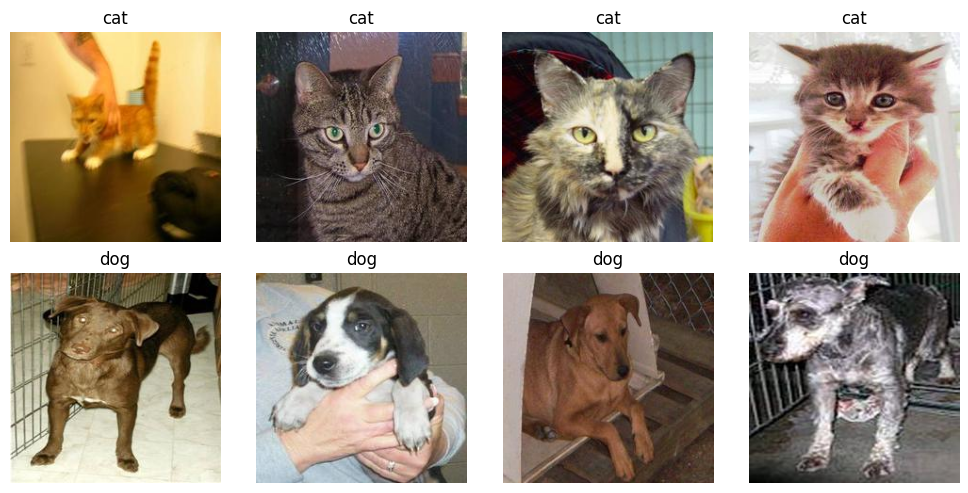

Verificación de datos completada


In [6]:
datasets = {}
names = set()
for split in ("train", "val", "test"):
    dataset = datasets[split] = load_dataset(DATA_DIR, split)
    counts = Counter(dataset.targets)
    by_class = {label: counts[index] for label, index in dataset.class_to_idx.items()}
    print(f"{split}: {len(dataset)} imágenes; {by_class}")
    expected = {label: manifest["counts"][label][split] for label in ("cat", "dog")}
    if by_class != expected:
        raise ValueError(f"Los conteos de {split} no coinciden con el manifiesto")
    if EXPECTED_COUNTS is not None:
        total = EXPECTED_COUNTS[split]
        if len(dataset) != total or set(counts.values()) != {total // 2}:
            raise ValueError(f"Conteos inesperados en {split}; revisa EXPECTED_COUNTS")
    if min(by_class.values()) <= 0:
        raise ValueError(f"Faltan ejemplos de una clase en {split}")
    for path, _ in dataset.samples:
        name = Path(path).name
        if name in names:
            raise ValueError(f"Nombre repetido entre conjuntos: {name}")
        names.add(name)
        with Image.open(path) as image:
            if image.size != (224, 224) or image.mode != "RGB":
                raise ValueError(f"Se esperaba RGB 224 × 224: {path}")

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for label in range(2):
    examples = [p for p, target in datasets["train"].samples if target == label][:4]
    for ax in axes[label]:
        ax.axis("off")
    for ax, path in zip(axes[label], examples):
        with Image.open(path) as image:
            ax.imshow(image)
        ax.set_title(datasets["train"].classes[label])
fig.tight_layout()
fig.savefig(INSPECTION_DIR / "examples.png")
plt.show()
plt.close(fig)
print("Verificación de datos completada")

## 5. Arquitectura y dispositivo (`src/model.py`)
Cuatro bloques Conv 3×3 → BatchNorm → ReLU → MaxPool, con 32, 64, 128 y 256 canales.
El pooling global reduce la entrada del clasificador a 256 características. La salida
son dos logits: `cat=0`, `dog=1`. Los checkpoints de la arquitectura antigua de dos
convoluciones no son compatibles. Se usa una sola GPU; también funciona en CPU.

In [7]:
class CatDogCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Cuatro bloques convolucionales con normalización y reducción espacial.
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d(1),
        )

        # Capa totalmente conectada para clasificación binaria
        self.classifier = nn.Sequential(
            # El pooling global deja una característica por cada uno de los 256 canales.
            nn.Flatten(), nn.Linear(256, 128), nn.ReLU(),
            # Dropout con probabilidad de 0.5 para evitar sobreajuste
            nn.Dropout(0.5), nn.Linear(128, 2),
        )

    # Método forward que define cómo los datos pasan a través del modelo
    def forward(self, images):
        return self.classifier(self.features(images))

def select_device(name="auto"):
    if name == "auto":
        name = "cuda" if torch.cuda.is_available() else "cpu"
    if name == "cuda" and not torch.cuda.is_available():
        raise ValueError("CUDA no está disponible; usa --device cpu.")
    if name == "cpu":
        torch.set_num_threads(min(4, torch.get_num_threads()))
    return torch.device(name)

def load_checkpoint(path: Path, device):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    if checkpoint["class_to_idx"] != {"cat": 0, "dog": 1}:
        raise ValueError("El checkpoint no tiene las clases esperadas.")
    model = CatDogCNN()
    model.load_state_dict(checkpoint["model_state_dict"])
    return model.to(device).eval(), checkpoint

## 6. Inspeccionar dimensiones (`src/03_inspect_model.py`)
Esta celda solo inspecciona un modelo temporal. El entrenamiento crea un modelo nuevo
tras restablecer la semilla para que la inspección no cambie su inicialización.

In [8]:
device = select_device(DEVICE_NAME)
seed_everything(SEED)
print("Dispositivo:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))
inspection_model = CatDogCNN().eval()
print(inspection_model)
x = torch.zeros(1, 3, 224, 224)
with torch.inference_mode():
    for layer in [*inspection_model.features, *inspection_model.classifier]:
        x = layer(x)
        print(f"{type(layer).__name__:20s} → {tuple(x.shape)}")
assert x.shape == (1, 2)
print(f"Parámetros entrenables: {sum(p.numel() for p in inspection_model.parameters()):,}")
del inspection_model, x

Dispositivo: cuda
GPU: Tesla T4
CatDogCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (13): 

## 7. Entrenar (`src/04_train.py`)
Adam con `lr=0.001` y `weight_decay=0.0001` por defecto. Se mantiene CrossEntropyLoss
sobre logits, sin softmax en entrenamiento. Se guarda el checkpoint de menor pérdida
de validación. Test no interviene en el entrenamiento ni en la selección del modelo.

Para inspeccionar sin entrenar: `RUN_TRAINING=False`. Si además configuras
`EXISTING_CHECKPOINT`, las etapas siguientes permiten evaluar y predecir con ese modelo.

In [9]:
def run_epoch(model, loader, device, optimizer=None, max_batches=None):
    training = optimizer is not None
    model.train(training)
    loss_sum = correct = total = 0
    criterion = nn.CrossEntropyLoss()
    with torch.set_grad_enabled(training):
        for batch_index, (images, labels) in enumerate(loader):
            if max_batches is not None and batch_index >= max_batches:
                break
            images, labels = images.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise ValueError("La pérdida no es finita.")
            if training:
                loss.backward()
                optimizer.step()
            loss_sum += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return loss_sum / total, correct / total

In [10]:
checkpoint_path = Path(EXISTING_CHECKPOINT) if EXISTING_CHECKPOINT is not None else None
history = []
if RUN_TRAINING:
    # Una carpeta nueva evita mezclar resultados al repetir esta celda.
    training_dir = new_output(RUN_DIR / ("training_" + datetime.now().strftime("%H%M%S_%f")))
    checkpoint_path = training_dir / "best_model.pt"
    seed_everything(SEED)
    train_loader = make_loader(datasets["train"], EFFECTIVE_BATCH_SIZE, shuffle=True, seed=SEED)
    val_loader = make_loader(datasets["val"], EFFECTIVE_BATCH_SIZE)
    config = dict(data=str(DATA_DIR.resolve()), output=str(training_dir.resolve()),
                  epochs=TRAIN_EPOCHS, batch_size=EFFECTIVE_BATCH_SIZE, lr=LEARNING_RATE,
                  weight_decay=WEIGHT_DECAY, seed=SEED, split_seed=manifest["seed"],
                  device_used=str(device), smoke_test=SMOKE_TEST, max_batches=MAX_BATCHES,
                  class_to_idx=datasets["train"].class_to_idx,
                  architecture="conv32-conv64-conv128-conv256-bn-gap-fc128-dropout0.5-fc2",
                  input_size=[3, 224, 224], torch_version=str(torch.__version__),
                  torchvision_version=str(__import__("torchvision").__version__))
    write_json(training_dir / "config.json", config)
    if SMOKE_TEST:
        print("PRUEBA TÉCNICA: las métricas no representan rendimiento final.")
    model = CatDogCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    best_loss = float("inf")
    with (training_dir / "history.csv").open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=["epoch", "train_loss", "train_accuracy", "val_loss", "val_accuracy"])
        writer.writeheader()
        for epoch in range(1, TRAIN_EPOCHS + 1):
            train_loss, train_acc = run_epoch(model, train_loader, device, optimizer, MAX_BATCHES)
            val_loss, val_acc = run_epoch(model, val_loader, device, max_batches=MAX_BATCHES)
            row = dict(epoch=epoch, train_loss=train_loss, train_accuracy=train_acc,
                       val_loss=val_loss, val_accuracy=val_acc)
            history.append(row)
            writer.writerow(row)
            handle.flush()
            print(f"Época {epoch}/{TRAIN_EPOCHS}: train loss={train_loss:.4f} acc={train_acc:.4f}; "
                  f"val loss={val_loss:.4f} acc={val_acc:.4f}", flush=True)
            if val_loss < best_loss:
                best_loss = val_loss
                torch.save({"model_state_dict": model.state_dict(), "epoch": epoch,
                            "val_loss": val_loss, "class_to_idx": datasets["train"].class_to_idx,
                            "config": config}, checkpoint_path)
    print("Mejor modelo:", checkpoint_path)
else:
    print("Entrenamiento omitido. Checkpoint:", checkpoint_path)

Época 1/20: train loss=0.6286 acc=0.6379; val loss=0.5891 acc=0.6765
Época 2/20: train loss=0.5710 acc=0.7070; val loss=0.7686 acc=0.6024
Época 3/20: train loss=0.5329 acc=0.7403; val loss=0.5439 acc=0.7336
Época 4/20: train loss=0.5095 acc=0.7579; val loss=0.4673 acc=0.7821
Época 5/20: train loss=0.4849 acc=0.7750; val loss=0.5390 acc=0.7405
Época 6/20: train loss=0.4591 acc=0.7913; val loss=0.5122 acc=0.7472
Época 7/20: train loss=0.4348 acc=0.8043; val loss=0.5330 acc=0.7381
Época 8/20: train loss=0.4002 acc=0.8233; val loss=0.3735 acc=0.8405
Época 9/20: train loss=0.3721 acc=0.8386; val loss=0.3731 acc=0.8312
Época 10/20: train loss=0.3471 acc=0.8529; val loss=0.3114 acc=0.8701
Época 11/20: train loss=0.3221 acc=0.8673; val loss=0.2857 acc=0.8757
Época 12/20: train loss=0.3061 acc=0.8749; val loss=0.6082 acc=0.7771
Época 13/20: train loss=0.2786 acc=0.8869; val loss=0.5225 acc=0.7795
Época 14/20: train loss=0.2622 acc=0.8970; val loss=0.4556 acc=0.8144
Época 15/20: train loss=0.248

## 8. Curvas de aprendizaje
La pérdida y la exactitud de train se miden durante el ajuste con Dropout activo;
val se mide en modo evaluación. Interpreta ambas curvas teniendo esto en cuenta.

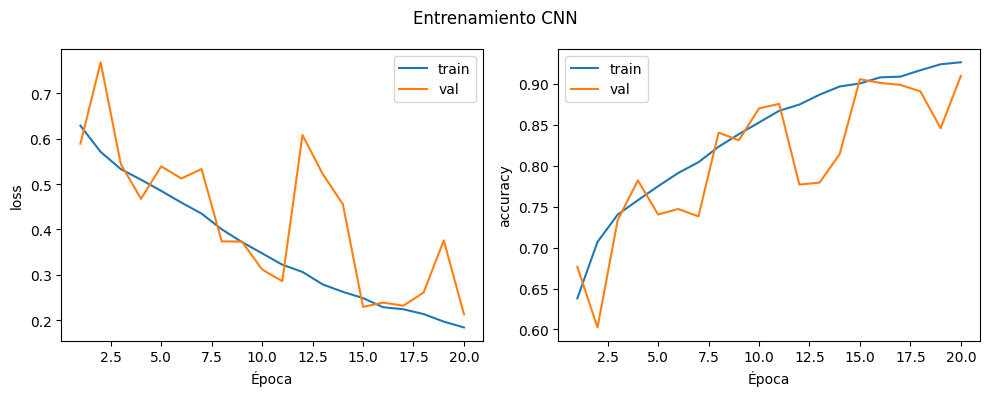

In [11]:
if history:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for ax, metric in zip(axes, ("loss", "accuracy")):
        for split in ("train", "val"):
            ax.plot([r["epoch"] for r in history], [r[f"{split}_{metric}"] for r in history], label=split)
        ax.set(xlabel="Época", ylabel=metric)
        ax.legend()
    fig.suptitle("PRUEBA TÉCNICA" if SMOKE_TEST else "Entrenamiento CNN")
    fig.tight_layout()
    fig.savefig(training_dir / "curves.png")
    plt.show()
    plt.close(fig)
else:
    print("No hay entrenamiento nuevo para graficar.")

## 9. Evaluar el mejor checkpoint (`src/05_evaluate.py`)
Se calculan accuracy, precision, recall y F1 por clase, además de la matriz de confusión
(filas reales, columnas predichas). Evalúa test al terminar de seleccionar el modelo
con validación. En modo smoke se evalúan pocos lotes ordenados; pueden contener solo
gatos, por lo que sus métricas no permiten concluir nada sobre la clasificación.

Accuracy: 0.9101; imágenes: 3750/3750
              precision    recall  f1-score   support

         cat       0.88      0.96      0.91      1875
         dog       0.95      0.86      0.91      1875

    accuracy                           0.91      3750
   macro avg       0.91      0.91      0.91      3750
weighted avg       0.91      0.91      0.91      3750



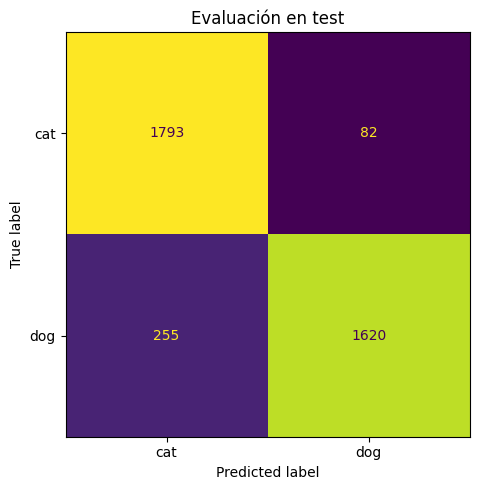

In [12]:
if checkpoint_path is not None:
    evaluation_dir = new_output(RUN_DIR / ("evaluation_" + datetime.now().strftime("%H%M%S_%f")))
    evaluation_model, checkpoint = load_checkpoint(checkpoint_path, device)
    test = datasets["test"]
    truth, predictions = [], []
    with torch.inference_mode():
        for index, (images, labels) in enumerate(make_loader(test, EFFECTIVE_BATCH_SIZE)):
            if MAX_BATCHES is not None and index >= MAX_BATCHES:
                break
            predictions.extend(evaluation_model(images.to(device)).argmax(1).cpu().tolist())
            truth.extend(labels.tolist())
    smoke = checkpoint["config"].get("smoke_test", False) or SMOKE_TEST
    report = classification_report(truth, predictions, labels=[0, 1],
                                   target_names=test.classes, output_dict=True, zero_division=0)
    matrix = confusion_matrix(truth, predictions, labels=[0, 1])
    results = dict(smoke_test=smoke, checkpoint=str(checkpoint_path.resolve()),
                   checkpoint_epoch=checkpoint["epoch"], samples_evaluated=len(truth),
                   total_test_samples=len(test), accuracy=accuracy_score(truth, predictions),
                   classification_report=report, confusion_matrix=matrix.tolist())
    write_json(evaluation_dir / "metrics.json", results)
    if smoke:
        print("PRUEBA TÉCNICA: estas métricas no representan rendimiento final.")
    print(f"Accuracy: {results['accuracy']:.4f}; imágenes: {len(truth)}/{len(test)}")
    print(classification_report(truth, predictions, labels=[0, 1], target_names=test.classes, zero_division=0))
    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay(matrix, display_labels=test.classes).plot(ax=ax, colorbar=False)
    ax.set_title("PRUEBA TÉCNICA" if smoke else "Evaluación en test")
    fig.tight_layout()
    fig.savefig(evaluation_dir / "confusion_matrix.png")
    plt.show()
    plt.close(fig)
    del evaluation_model
else:
    print("Evaluación omitida: entrena o configura EXISTING_CHECKPOINT.")

## 10. Predecir una imagen (`src/06_predict.py`)
Configura `IMAGE_PATH` con una foto accesible desde el notebook y ejecuta esta celda.
Se carga el mejor checkpoint y se usa exactamente el mismo preprocesamiento.
Los valores softmax no son una medida calibrada de certeza.

In [13]:
if IMAGE_PATH is not None:
    if checkpoint_path is None:
        raise ValueError("Entrena o configura EXISTING_CHECKPOINT antes de predecir")
    prediction_model, prediction_checkpoint = load_checkpoint(checkpoint_path, device)
    with Image.open(Path(IMAGE_PATH)) as image:
        tensor = image_tensor(image).unsqueeze(0).to(device)
        preview = ImageOps.exif_transpose(image).convert("RGB").copy()
    with torch.inference_mode():
        probabilities = prediction_model(tensor).softmax(dim=1)[0].cpu()
    classes = sorted(prediction_checkpoint["class_to_idx"], key=prediction_checkpoint["class_to_idx"].get)
    label = classes[probabilities.argmax().item()]
    if prediction_checkpoint["config"].get("smoke_test", False):
        print("PRUEBA TÉCNICA: modelo sin entrenamiento completo.")
    print("Predicción:", label)
    for name, probability in zip(classes, probabilities.tolist()):
        print(f"{name}: {probability:.2%}")
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(preview)
    ax.set_title(label)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "prediction.png")
    plt.show()
    plt.close(fig)
    write_json(RUN_DIR / "prediction.json", dict(image=str(IMAGE_PATH), checkpoint=str(checkpoint_path),
               prediction=label, probabilities=dict(zip(classes, probabilities.tolist()))))
    del prediction_model
else:
    print("Predicción opcional omitida. Configura IMAGE_PATH para clasificar una foto.")

Predicción opcional omitida. Configura IMAGE_PATH para clasificar una foto.


## 11. Archivos generados
Los resultados incluyen ejemplos, configuración, historial CSV, curvas, mejor modelo,
métricas JSON y matriz de confusión. La predicción opcional añade PNG y JSON.
Las celdas de entrenamiento y evaluación crean subcarpetas nuevas al repetirse.
Para descargar los resultados desde Kaggle, guarda una versión del notebook y consulta
sus archivos de salida. La preparación queda en `WORK_ROOT/dataset`, separada de cada ejecución.

In [14]:
print("Directorio de esta ejecución:", RUN_DIR.resolve())
for path in sorted(RUN_DIR.rglob("*")):
    if path.is_file():
        print(f"{path.relative_to(RUN_DIR)} ({path.stat().st_size / 1024:.1f} KB)")
print("Pipeline completado.")

Directorio de esta ejecución: /kaggle/working/run_20261021_025840_725187
evaluation_034539_381769/confusion_matrix.png (13.7 KB)
evaluation_034539_381769/metrics.json (1.0 KB)
inspection/examples.png (618.3 KB)
training_032358_277072/best_model.pt (1663.0 KB)
training_032358_277072/config.json (0.5 KB)
training_032358_277072/curves.png (51.0 KB)
training_032358_277072/history.csv (1.6 KB)
Pipeline completado.


## 12. Conclusiones

### Lectura de los resultados

La CNN entrenada desde cero **sí aprendió a distinguir gatos y perros**. Se utilizaron
25 000 imágenes balanceadas, divididas en 17 500 para entrenamiento, 3 750 para
validación y 3 750 para prueba. La ejecución completó **20 épocas**, con batch de 32,
Adam, learning rate de 0,001 y `weight_decay=0.0001`; no fue una prueba smoke.

| Indicador | Resultado observado |
|---|---:|
| Accuracy de train, época 1 → época 20 | 63,79 % → 92,66 % |
| Pérdida de train, época 1 → época 20 | 0,6286 → 0,1836 |
| Accuracy de validación, época 20 | 90,99 % |
| Menor pérdida de validación | 0,2131, en la época 20 |
| Accuracy en test | 91,01 %: 3 413 aciertos de 3 750 imágenes |
| Errores en test | 337 imágenes: 8,99 % |
| Parámetros entrenables | 422 050 |

El checkpoint seleccionado corresponde a la época 20 porque obtuvo la menor pérdida
de validación. La exactitud de validación y la de test son cercanas, lo que es
compatible con una generalización similar entre estas dos particiones del dataset.
Esto no demuestra el mismo rendimiento en fotos de otra procedencia.

La matriz de confusión permite precisar dónde falla el modelo:

| Clase real | Predicción: gato | Predicción: perro | Recall de la clase |
|---|---:|---:|---:|
| Gato | 1 793 | 82 | 95,63 % |
| Perro | 255 | 1 620 | 86,40 % |

Los gatos tienen una precisión de **87,55 %** y los perros de **95,18 %**. El modelo
recupera una mayor proporción de gatos reales, mientras que sus predicciones de perro
son más precisas. El F1 por clase es aproximadamente **0,91** en ambos casos; este
resumen no debe ocultar la diferencia de recall entre clases.

### Qué funcionó

- **El entrenamiento produjo una mejora sostenida en train.** La pérdida disminuyó
  y la exactitud aumentó durante las 20 épocas. El resultado de test es muy superior
  al 50 % de referencia de predecir siempre una misma clase en este conjunto balanceado.
- **La arquitectura compacta fue suficiente para esta tarea.** Los cuatro bloques
  convolucionales y el pooling global lograron 91,01 % en test con 422 050 parámetros.
  No se necesita una capa densa de millones de pesos para obtener este resultado.
- **Se separaron ajuste, selección y evaluación.** Train ajustó los pesos, val eligió
  el checkpoint por pérdida y test se utilizó para evaluar ese checkpoint.
- **El flujo se ejecutó en Kaggle con una GPU Tesla T4** y dejó historial, curvas,
  métricas y pesos guardados, lo que permite revisar y reutilizar el experimento.

Se utilizaron BatchNorm, Dropout y `weight_decay`, pero esta única ejecución no
permite atribuir a cada componente una mejora concreta. Para demostrar su aporte
haría falta compararlos en experimentos controlados con y sin cada componente.

### Qué no funcionó tan bien y qué no se comprobó

- **La validación tuvo oscilaciones importantes.** Por ejemplo, su pérdida pasó de
  0,2857 en la época 11 a 0,6082 en la 12. También hubo retrocesos en las épocas 13
  y 19. Estas variaciones muestran inestabilidad, pero no identifican por sí solas
  su causa ni prueban sobreajuste severo; la mejor pérdida llegó finalmente en la época 20.
- **Se confundieron más perros con gatos.** Hubo 255 errores perro → gato y 82 gato
  → perro, pese a que test tiene 1 875 imágenes de cada clase. El recall de perros
  es el aspecto de clasificación que requiere mayor atención.
- **La accuracy final de train superó a la de validación en 1,67 puntos porcentuales.**
  La diferencia es moderada y debe interpretarse con cuidado: train se midió durante
  el ajuste con Dropout activo, y val en modo evaluación.
- **No se ejecutó la predicción de una foto externa.** `IMAGE_PATH=None` hizo que ese
  bloque se omitiera. La evidencia disponible procede de la evaluación en test.
- **Faltan comparaciones y mediciones.** No hay varias semillas, una comparación con
  la CNN anterior o una medición dedicada de latencia de inferencia. La comprobación
  de nombres únicos tampoco descarta duplicados visuales con nombres distintos.

### Qué mejoraría en una siguiente versión

1. **Revisar ejemplos mal clasificados**, especialmente perros predichos como gatos,
   y comprobar etiquetas y duplicados visuales. Esto ayudaría a formular hipótesis
   sobre los errores; no se ha comprobado todavía que se deban al fondo, la raza o la pose.
2. **Probar aumentación solo en train**, con volteos horizontales y recortes moderados,
   y conservar las proporciones al preparar nuevas imágenes. Mantendría val y test
   con transformaciones deterministas. El [tutorial oficial de PyTorch](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html)
   muestra la separación entre aumentación de entrenamiento y preprocesamiento de evaluación.
3. **Comparar tasas de aprendizaje y un scheduler**, por ejemplo
   [ReduceLROnPlateau](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html),
   que reduce la tasa cuando una métrica deja de mejorar. Lo evaluaría como una posible
   ayuda ante las oscilaciones, sin asumir que el learning rate es la causa demostrada.
4. **Repetir con varias semillas y comparar configuraciones** de `weight_decay`, Dropout
   y, como alternativa, una ResNet18 preentrenada. Seleccionaría los cambios usando val,
   vigilando el recall de perros y el F1 macro, y reservaría test para la evaluación final.
5. **Medir inferencia y probar fotos externas.** Registraría latencia con calentamiento,
   tamaño de lote y sincronización CUDA definidos, además de observar errores en imágenes
   ajenas al dataset. Si se prueba parada temprana, su paciencia debe tolerar las oscilaciones:
   en esta ejecución una parada prematura podría haber descartado la mejor época.

Estas propuestas son experimentos pendientes; este notebook no demuestra todavía
que aumenten la exactitud ni permite prometer un porcentaje de mejora.

## 13. Herramientas utilizadas

| Categoría | Herramienta | Uso concreto en este notebook |
|---|---|---|
| Lenguaje | Python 3.13.15 | Código y ejecución de las celdas, según los metadatos del kernel. |
| Framework de aprendizaje profundo | PyTorch 2.11.0+cu128 | Tensores, autograd, CNN con `torch.nn`, CrossEntropyLoss, Adam, ejecución en CUDA y guardado/carga de checkpoints `.pt`. |
| Visión computacional | Torchvision 0.26.0+cu128 | `ImageFolder` para cargar imágenes por clase y `ToTensor` para convertirlas en tensores en [0, 1]. |
| Cálculo numérico | NumPy | Fijar la semilla del generador aleatorio mediante `np.random.seed`; las operaciones de la red se realizan con PyTorch. |
| Visualización | Matplotlib | Cuadrícula de ejemplos, curvas de pérdida y accuracy y visualización/guardado de figuras. |
| Evaluación | scikit-learn | Accuracy, precision, recall, F1, matriz de confusión y `ConfusionMatrixDisplay`. |
| Procesamiento de imágenes | Pillow (`PIL`) | Abrir imágenes, corregir orientación EXIF, convertir a RGB y redimensionar a 224 × 224. |
| Utilidades | Biblioteca estándar de Python | `pathlib`, `json`, `csv`, `random`, `datetime` y `collections` para rutas, registro, división reproducible y resultados; `zipfile` y `shutil` para fuentes ZIP cuando se utilizan. |
| Entorno | Kaggle Notebooks | Ejecución interactiva, datos de entrada en `/kaggle/input` y resultados en `/kaggle/working`. |
| Aceleración | GPU NVIDIA Tesla T4 mediante CUDA | Dispositivo utilizado por esta ejecución, según la salida del bloque de inspección. |

Las versiones de NumPy, Matplotlib, scikit-learn y Pillow no quedaron impresas en
las salidas, por lo que no se les asigna una versión supuesta. Se fijó la semilla 42
y se solicitaron algoritmos deterministas, sin que ello garantice igualdad entre
hardware o versiones diferentes.

El bloque de entrenamiento duró aproximadamente **1300.72 segundos**
(**21 minutos y 40,72 segundos**), calculados a partir de sus metadatos de ejecución;
ese intervalo incluye validación y guardado de checkpoints, y excluye preparación
e inspección. El checkpoint local `models/best_model.pt`, cuya configuración corresponde
a esta ejecución, ocupa **1.702901 MB** (1 MB = 1 000 000 bytes).
No se registró una medición específica del tiempo de inferencia por imagen.